# Fine-tuning YOLOv8m per il rilevamento dei palloni

Notebook per addestrare un detector **YOLOv8m pretrained** sulla classe `ball`, usando gli split train/validation/test già presenti. L'addestramento usa la GPU NVIDIA con CUDA se PyTorch la rileva; in assenza di CUDA seleziona esplicitamente la CPU e un batch più piccolo. La CPU può richiedere molto tempo.

Le metriche riportate sono di **object detection**: precision, recall, mAP@0.50 e mAP@0.50:0.95. La mAP non è accuracy di classificazione. La validation guida la selezione del checkpoint; il test, se presente e valido, viene valutato separatamente solo dopo il training.

Il notebook non estrae frame dai video e non modifica il dataset originale. Al primo avvio può essere necessario Internet per installare Ultralytics e scaricare i pesi pretrained.

In [1]:
from pathlib import Path
from datetime import datetime
import sys

# Il notebook si aspetta di essere avviato dalla cartella di lavoro o da una sua sottocartella.
DATASET_NAME = "Volleyball Ball Tracking.v1i.yolov8"
DATASET_DIR = next(
    (candidate for base in (Path.cwd(), *Path.cwd().parents)
     for candidate in [base if base.name == DATASET_NAME else base / DATASET_NAME]
     if candidate.is_dir()),
    None,
)
if DATASET_DIR is None:
    raise FileNotFoundError(
        f"Dataset '{DATASET_NAME}' non trovato a partire da {Path.cwd()}. "
        "Avvia il notebook dalla cartella di lavoro oppure imposta DATASET_DIR manualmente."
    )
DATASET_DIR = DATASET_DIR.resolve()
WORKSPACE_DIR = DATASET_DIR.parent
OUTPUT_ROOT = WORKSPACE_DIR / "runs" / "volleyball_ball"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Parametri modificabili prima del training.
PRETRAINED_WEIGHTS_PATH = WORKSPACE_DIR / "yolov8m.pt"  # checkpoint già presente nella cartella di lavoro
EPOCHS = 100
PATIENCE = 20
IMAGE_SIZE = 640
GPU_BATCH_SIZE = 16
CPU_BATCH_SIZE = 4
WORKERS = 0  # scelta conservativa per compatibilità con Windows/notebook
SEED = 42

print(f"Workspace: {WORKSPACE_DIR}")
print(f"Dataset:   {DATASET_DIR}")
print(f"Output:    {OUTPUT_ROOT}")

Workspace: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP
Dataset:   C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\Volleyball Ball Tracking.v1i.yolov8
Output:    C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_ball


## Dipendenze e dispositivo

Il notebook verifica le dipendenze nell'interprete del kernel e non installa o sostituisce pacchetti al suo interno. Se manca `ultralytics`, usa l'ambiente isolato descritto più sotto, selezionalo come kernel e riavvia il notebook. Anche PyTorch e torchvision vanno corretti in un ambiente separato, non durante una sessione attiva.

In [2]:
import importlib.util
if importlib.util.find_spec("ultralytics") is None:
    raise ModuleNotFoundError(
        "Ultralytics non è installato in questo kernel. Crea l'ambiente isolato descritto "
        "nella sezione NMS, installa lì le dipendenze e selezionalo come kernel Jupyter."
    )

import torch
from ultralytics import YOLO

CUDA_AVAILABLE = torch.cuda.is_available()
if CUDA_AVAILABLE:
    DEVICE = 0
    BATCH_SIZE = GPU_BATCH_SIZE
    print(f"Dispositivo: GPU CUDA — {torch.cuda.get_device_name(0)}")
    print(f"PyTorch {torch.__version__}; CUDA runtime {torch.version.cuda}")
else:
    DEVICE = "cpu"
    BATCH_SIZE = CPU_BATCH_SIZE
    print("Dispositivo: CPU (fallback esplicito)")
    print(f"PyTorch {torch.__version__}; CUDA runtime compilato: {torch.version.cuda}")
    if torch.version.cuda is None:
        print("Diagnostica: questa installazione di PyTorch è CPU-only. Per CUDA installare una build PyTorch adatta al sistema e riavviare il kernel.")
    else:
        print("Diagnostica: PyTorch include CUDA ma non rileva una GPU utilizzabile; verificare driver NVIDIA, compatibilità CUDA e disponibilità della GPU.")
print(f"Batch selezionato: {BATCH_SIZE}; workers: {WORKERS}")

Dispositivo: GPU CUDA — NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU
PyTorch 2.14.1+cu130; CUDA runtime 13.0
Batch selezionato: 16; workers: 0


In [3]:
import torchvision

print(
    f"Diagnostica NMS — torch {torch.__version__} (CUDA build {torch.version.cuda}), "
    f"torchvision {torchvision.__version__}; GPU rilevata: {CUDA_AVAILABLE}"
)
print(
    f"Interprete: {sys.executable}; Python {sys.version.split()[0]}; "
    f"operatori nativi torchvision: {torchvision.extension._has_ops()}"
)

def run_nms_smoke_test(device):
    boxes = torch.tensor(
        [[0.0, 0.0, 10.0, 10.0], [1.0, 1.0, 11.0, 11.0]],
        dtype=torch.float32,
        device=device,
    )
    scores = torch.tensor([0.9, 0.8], dtype=torch.float32, device=device)
    keep = torchvision.ops.nms(boxes, scores, 0.5).tolist()
    if keep != [0]:
        raise RuntimeError(f"Risultato inatteso dal test NMS su {device}: {keep}")
    return keep

run_nms_smoke_test("cpu")
print("NMS CPU: OK")

if CUDA_AVAILABLE:
    try:
        run_nms_smoke_test("cuda:0")
    except NotImplementedError as exc:
        error_text = str(exc)
        if "torchvision::nms" not in error_text or "CUDA" not in error_text:
            raise
        print(
            "ATTENZIONE: questa build di torchvision non ha il kernel CUDA per "
            "torchvision.ops.nms. Il preflight ha verificato il kernel CPU; "
            "il training userà la CPU e sarà più lento."
        )
        DEVICE = "cpu"
        BATCH_SIZE = CPU_BATCH_SIZE
        CUDA_NMS_AVAILABLE = False
    else:
        DEVICE = 0
        BATCH_SIZE = GPU_BATCH_SIZE
        CUDA_NMS_AVAILABLE = True
        print("NMS CUDA: OK; training GPU abilitato.")
else:
    DEVICE = "cpu"
    BATCH_SIZE = CPU_BATCH_SIZE
    CUDA_NMS_AVAILABLE = False
    print("NMS CUDA non testata: GPU non disponibile; training CPU.")

print(f"Dispositivo finale: {DEVICE}; batch: {BATCH_SIZE}")

Diagnostica NMS — torch 2.14.1+cu130 (CUDA build 13.0), torchvision 0.29.1+cu130; GPU rilevata: True
Interprete: c:\Users\SavarDar\AppData\Local\Programs\Python\Python314\python.exe; Python 3.14.6; operatori nativi torchvision: True
NMS CPU: OK
NMS CUDA: OK; training GPU abilitato.
Dispositivo finale: 0; batch: 16


### Ripristinare la GPU in un ambiente isolato (opt-in)

Il preflight mantiene la GPU solo se CUDA è disponibile **e** NMS CUDA passa. In questo interprete il traceback riporta `torch 2.14.1+cu130` ma `torchvision 0.29.2+cpu`: la build torchvision è CPU-only, coerente con il kernel NMS CUDA mancante. Per non alterare l'ambiente attivo, crea un virtual environment separato da PowerShell dalla cartella di lavoro e selezionalo poi come kernel Jupyter:

```powershell
$python = Join-Path $env:LOCALAPPDATA 'Programs\Python\Python314\python.exe'
& $python -m venv .venv-yolo-cuda
$venvPython = Join-Path (Get-Location) '.venv-yolo-cuda\Scripts\python.exe'
& $venvPython -m pip install --upgrade pip
& $venvPython -m pip install torch==2.14.1 torchvision==0.29.1 --index-url https://download.pytorch.org/whl/cu130
& $venvPython -m pip install ultralytics ipykernel
& $venvPython -m ipykernel install --user --name scout-yolo-cuda --display-name 'Python (Scout YOLO CUDA)'
```

La coppia `torch 2.14.1` / `torchvision 0.29.1` con CUDA 13.0 è indicata nella [tabella ufficiale PyTorch per versioni precedenti](https://pytorch.org/get-started/previous-versions/); gli indici ufficiali CUDA 13.0 pubblicano wheel Windows CPython 3.14 per entrambi ([torch](https://download.pytorch.org/whl/cu130/torch/) e [torchvision](https://download.pytorch.org/whl/cu130/torchvision/)). Il driver NVIDIA rilevato qui è 595.95 e la GPU RTX PRO 2000 Blackwell è visibile al runtime CUDA 13.0. Dopo l'installazione, riavvia/seleziona il kernel `Python (Scout YOLO CUDA)` e riesegui il notebook dall'inizio; non installare queste versioni nel kernel attivo.

## Checkpoint pretrained locale

Il checkpoint `yolov8m.pt` presente nella cartella di lavoro viene caricato direttamente da disco: non serve un download né alcuna modifica al trust store. Se sposti il file, aggiorna `PRETRAINED_WEIGHTS_PATH` nella cella di configurazione. Il notebook controlla che il file esista e non sia vuoto; in caso contrario si ferma prima del training e non parte da pesi casuali.

In [4]:
configured_weights = Path(PRETRAINED_WEIGHTS_PATH).expanduser()
if not configured_weights.is_absolute():
    configured_weights = WORKSPACE_DIR / configured_weights
if not configured_weights.is_file():
    raise FileNotFoundError(
        f"Checkpoint pretrained non trovato: {configured_weights}. "
        "Imposta PRETRAINED_WEIGHTS_PATH sul percorso locale corretto prima di avviare il training."
    )
if configured_weights.stat().st_size == 0:
    raise ValueError(f"Il checkpoint pretrained è vuoto: {configured_weights}")
RESOLVED_WEIGHTS = configured_weights.resolve()
print(f"Checkpoint pretrained locale: {RESOLVED_WEIGHTS} ({RESOLVED_WEIGHTS.stat().st_size:,} byte)")

Checkpoint pretrained locale: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\yolov8m.pt (52,136,884 byte)


## Controllo degli split e delle annotazioni

Controlla immagini, corrispondenza dei file `.txt`, formato YOLO normalizzato e indice di classe. Train e validation devono essere validi. Il test è facoltativo: se manca o contiene annotazioni non valide viene escluso, senza impedire l'addestramento. Gli split originali restano intatti; il file YAML assoluto viene scritto nella cartella dei risultati per gestire correttamente percorsi Windows con spazi e `&`.

In [5]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def inspect_split(split_name):
    split_dir = DATASET_DIR / split_name
    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"
    if not images_dir.is_dir() or not labels_dir.is_dir():
        return {"name": split_name, "valid": False, "reason": "manca images/ o labels/", "images": [], "labels": 0}

    images = sorted(p for p in images_dir.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    label_files = {p.stem: p for p in labels_dir.glob("*.txt")}
    errors = []
    if not images:
        errors.append("nessuna immagine")
    missing = [p.name for p in images if p.stem not in label_files]
    if missing:
        errors.append(f"{len(missing)} immagini senza etichetta YOLO")

    for label_path in label_files.values():
        try:
            for line_number, line in enumerate(label_path.read_text(encoding="utf-8").splitlines(), start=1):
                if not line.strip():
                    continue
                fields = line.split()
                if len(fields) != 5:
                    raise ValueError(f"riga {line_number}: attesi 5 valori")
                class_id = int(fields[0])
                box = [float(value) for value in fields[1:]]
                if class_id != 0:
                    raise ValueError(f"riga {line_number}: classe {class_id}, attesa 0 (ball)")
                xc, yc, box_width, box_height = box
                if (
                    not all(0.0 <= value <= 1.0 for value in box)
                    or box_width <= 0 or box_height <= 0
                    or xc - box_width / 2 < -1e-3 or xc + box_width / 2 > 1 + 1e-3
                    or yc - box_height / 2 < -1e-3 or yc + box_height / 2 > 1 + 1e-3
                ):
                    raise ValueError(f"riga {line_number}: coordinate non normalizzate o dimensioni non positive")
        except (OSError, ValueError) as exc:
            errors.append(f"{label_path.name}: {exc}")
            if len(errors) >= 10:
                break

    return {
        "name": split_name,
        "valid": not errors,
        "reason": "; ".join(errors),
        "images": images,
        "labels": len(label_files),
    }

splits = {name: inspect_split(name) for name in ("train", "valid", "test")}
for name, info in splits.items():
    status = "OK" if info["valid"] else f"NON VALIDO: {info['reason']}"
    print(f"{name:5} | {len(info['images']):4} immagini | {info['labels']:4} etichette | {status}")

for required_split in ("train", "valid"):
    if not splits[required_split]["valid"]:
        raise ValueError(f"Lo split {required_split} non è valido: {splits[required_split]['reason']}")

TEST_VALID = splits["test"]["valid"]
if not TEST_VALID:
    print(f"Test escluso dalla valutazione: {splits['test']['reason']}")

train | 1647 immagini | 1647 etichette | OK
valid |  185 immagini |  185 etichette | OK
test  |  192 immagini |  192 etichette | OK


In [6]:
import json

dataset_config = {
    "path": DATASET_DIR.as_posix(),
    "train": "train/images",
    "val": "valid/images",
    "names": {0: "ball"},
    "nc": 1,
}
if TEST_VALID:
    dataset_config["test"] = "test/images"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
DATA_YAML = OUTPUT_ROOT / "dataset_yolov8.yaml"
yaml_lines = [
    f"path: {json.dumps(dataset_config['path'], ensure_ascii=False)}",
    f"train: {dataset_config['train']}",
    f"val: {dataset_config['val']}",
    f"nc: {dataset_config['nc']}",
    "names: [ball]",
]
if TEST_VALID:
    yaml_lines.append(f"test: {dataset_config['test']}")
DATA_YAML.write_text("\n".join(yaml_lines) + "\n", encoding="utf-8")
print(DATA_YAML.read_text(encoding="utf-8"))

path: "C:/Users/SavarDar/OneDrive - Electrolux/Desktop/Scout_Volley_CV&NLP/Volleyball Ball Tracking.v1i.yolov8"
train: train/images
val: valid/images
nc: 1
names: [ball]
test: test/images



## Ispezione visiva mirata

Mostra alcuni esempi train con i bounding box letti dalle etichette YOLO. È un controllo visivo, non una metrica.

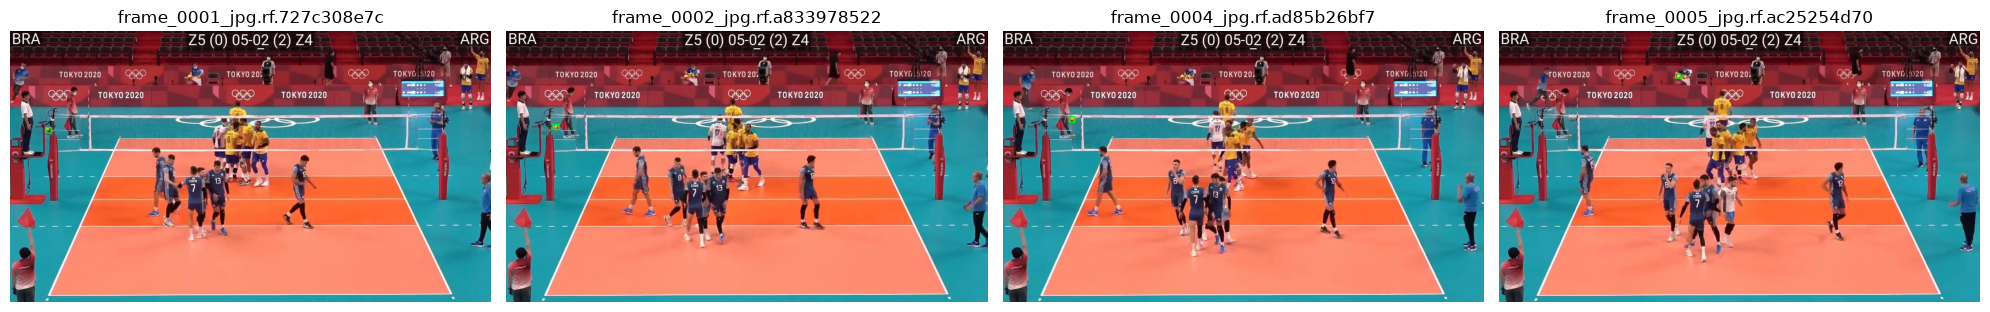

In [7]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

sample_images = splits["train"]["images"][:4]
fig, axes = plt.subplots(1, len(sample_images), figsize=(5 * len(sample_images), 4))
if len(sample_images) == 1:
    axes = [axes]
for ax, image_path in zip(axes, sample_images):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    label_path = DATASET_DIR / "train" / "labels" / f"{image_path.stem}.txt"
    width, height = image.size
    for line in label_path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        _, xc, yc, bw, bh = map(float, line.split())
        x1, y1 = (xc - bw / 2) * width, (yc - bh / 2) * height
        x2, y2 = (xc + bw / 2) * width, (yc + bh / 2) * height
        draw.rectangle((x1, y1, x2, y2), outline="lime", width=max(2, width // 400))
    ax.imshow(image)
    ax.set_title(image_path.name[:28])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Fine-tuning

Il training valida a ogni epoca sullo split `valid`; Ultralytics salva il checkpoint `best.pt` scelto sulla validation e i grafici del training. Il test non viene usato per scegliere il modello. Il tempo dipende dall'hardware; su CPU il training completo può essere molto lento.

In [8]:
RUN_NAME = "yolov8m_ball_" + datetime.now().strftime("%Y%m%d_%H%M%S")
model = YOLO(str(RESOLVED_WEIGHTS))
train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    workers=WORKERS,
    device=DEVICE,
    project=str(OUTPUT_ROOT),
    name=RUN_NAME,
    exist_ok=True,
    pretrained=True,
    seed=SEED,
    cache=False,
    plots=True,
    verbose=True,
)

TRAIN_RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = Path(model.trainer.best)
if not BEST_WEIGHTS.is_file():
    raise FileNotFoundError(f"Checkpoint best non trovato: {BEST_WEIGHTS}")
print(f"Checkpoint migliore: {BEST_WEIGHTS}")
print(f"Risultati training:  {TRAIN_RUN_DIR}")

Ultralytics 8.4.212  Python-3.14.6 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_ball\dataset_yolov8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C

## Valutazione del checkpoint migliore

Precision e recall sono le medie per classe di Ultralytics. `mAP50` è mAP@0.50 IoU; `mAP50-95` è la media su soglie IoU da 0.50 a 0.95. Il test viene eseguito una sola volta e solo se il controllo iniziale lo ha dichiarato valido.

In [10]:
import pandas as pd

best_model = YOLO(str(BEST_WEIGHTS))

def evaluate_split(split_name, eval_name):
    result = best_model.val(
        data=str(DATA_YAML),
        split=split_name,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        workers=WORKERS,
        device=DEVICE,
        project=str(OUTPUT_ROOT),
        name=eval_name,
        exist_ok=True,
        plots=True,
        verbose=True,
    )
    box = result.box
    row = {
        "split": split_name,
        "precision": float(box.mp),
        "recall": float(box.mr),
        "mAP50": float(box.map50),
        "mAP50-95": float(box.map),
        "immagini": len(splits["valid" if split_name == "val" else split_name]["images"]),
        "checkpoint": str(BEST_WEIGHTS),
    }
    return row, result

metric_rows = []
validation_row, validation_result = evaluate_split("val", "evaluation_validation")
metric_rows.append(validation_row)

test_result = None
if TEST_VALID:
    test_row, test_result = evaluate_split("test", "evaluation_test")
    metric_rows.append(test_row)

metrics = pd.DataFrame(metric_rows)
METRICS_CSV = TRAIN_RUN_DIR / "metriche_detection.csv"
metrics.to_csv(METRICS_CSV, index=False, float_format="%.6f")
display(metrics.round(4))
print(f"Metriche salvate in: {METRICS_CSV}")

Ultralytics 8.4.212  Python-3.14.6 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU, 8151MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 280.6±64.8 MB/s, size: 157.6 KB)
val: Scanning C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\Volleyball Ball Tracking.v1i.yolov8\valid\labels.cache... 185 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 185/185 77.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.2it/s 3.7s0.3s
                   all        185        185      0.834      0.953      0.961      0.515
Speed: 0.2ms preprocess, 8.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_ball\evaluation_validation
Ultralytics 8.4.212  Python-3.14.6 torch-2.14.1+cu130 CUDA:0 (N

,split,precision,recall,mAP50,mAP50-95,immagini,checkpoint
0,val,0.8343,0.9525,0.9608,0.5151,185,C:\Users\SavarDar\OneDrive - Electrolux\Deskto...
1,test,0.9209,0.9047,0.9518,0.5402,192,C:\Users\SavarDar\OneDrive - Electrolux\Deskto...


Metriche salvate in: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_ball\yolov8m_ball_20261114_172150\metriche_detection.csv


## Curve e artefatti

Gli output includono i grafici del training e quelli delle valutazioni (quando generati da Ultralytics), il checkpoint migliore e la tabella CSV delle metriche. I numeri diventano disponibili solo dopo aver eseguito training e valutazione: non sono inseriti risultati dimostrativi.

C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_ball\yolov8m_ball_20261114_172150\results.png


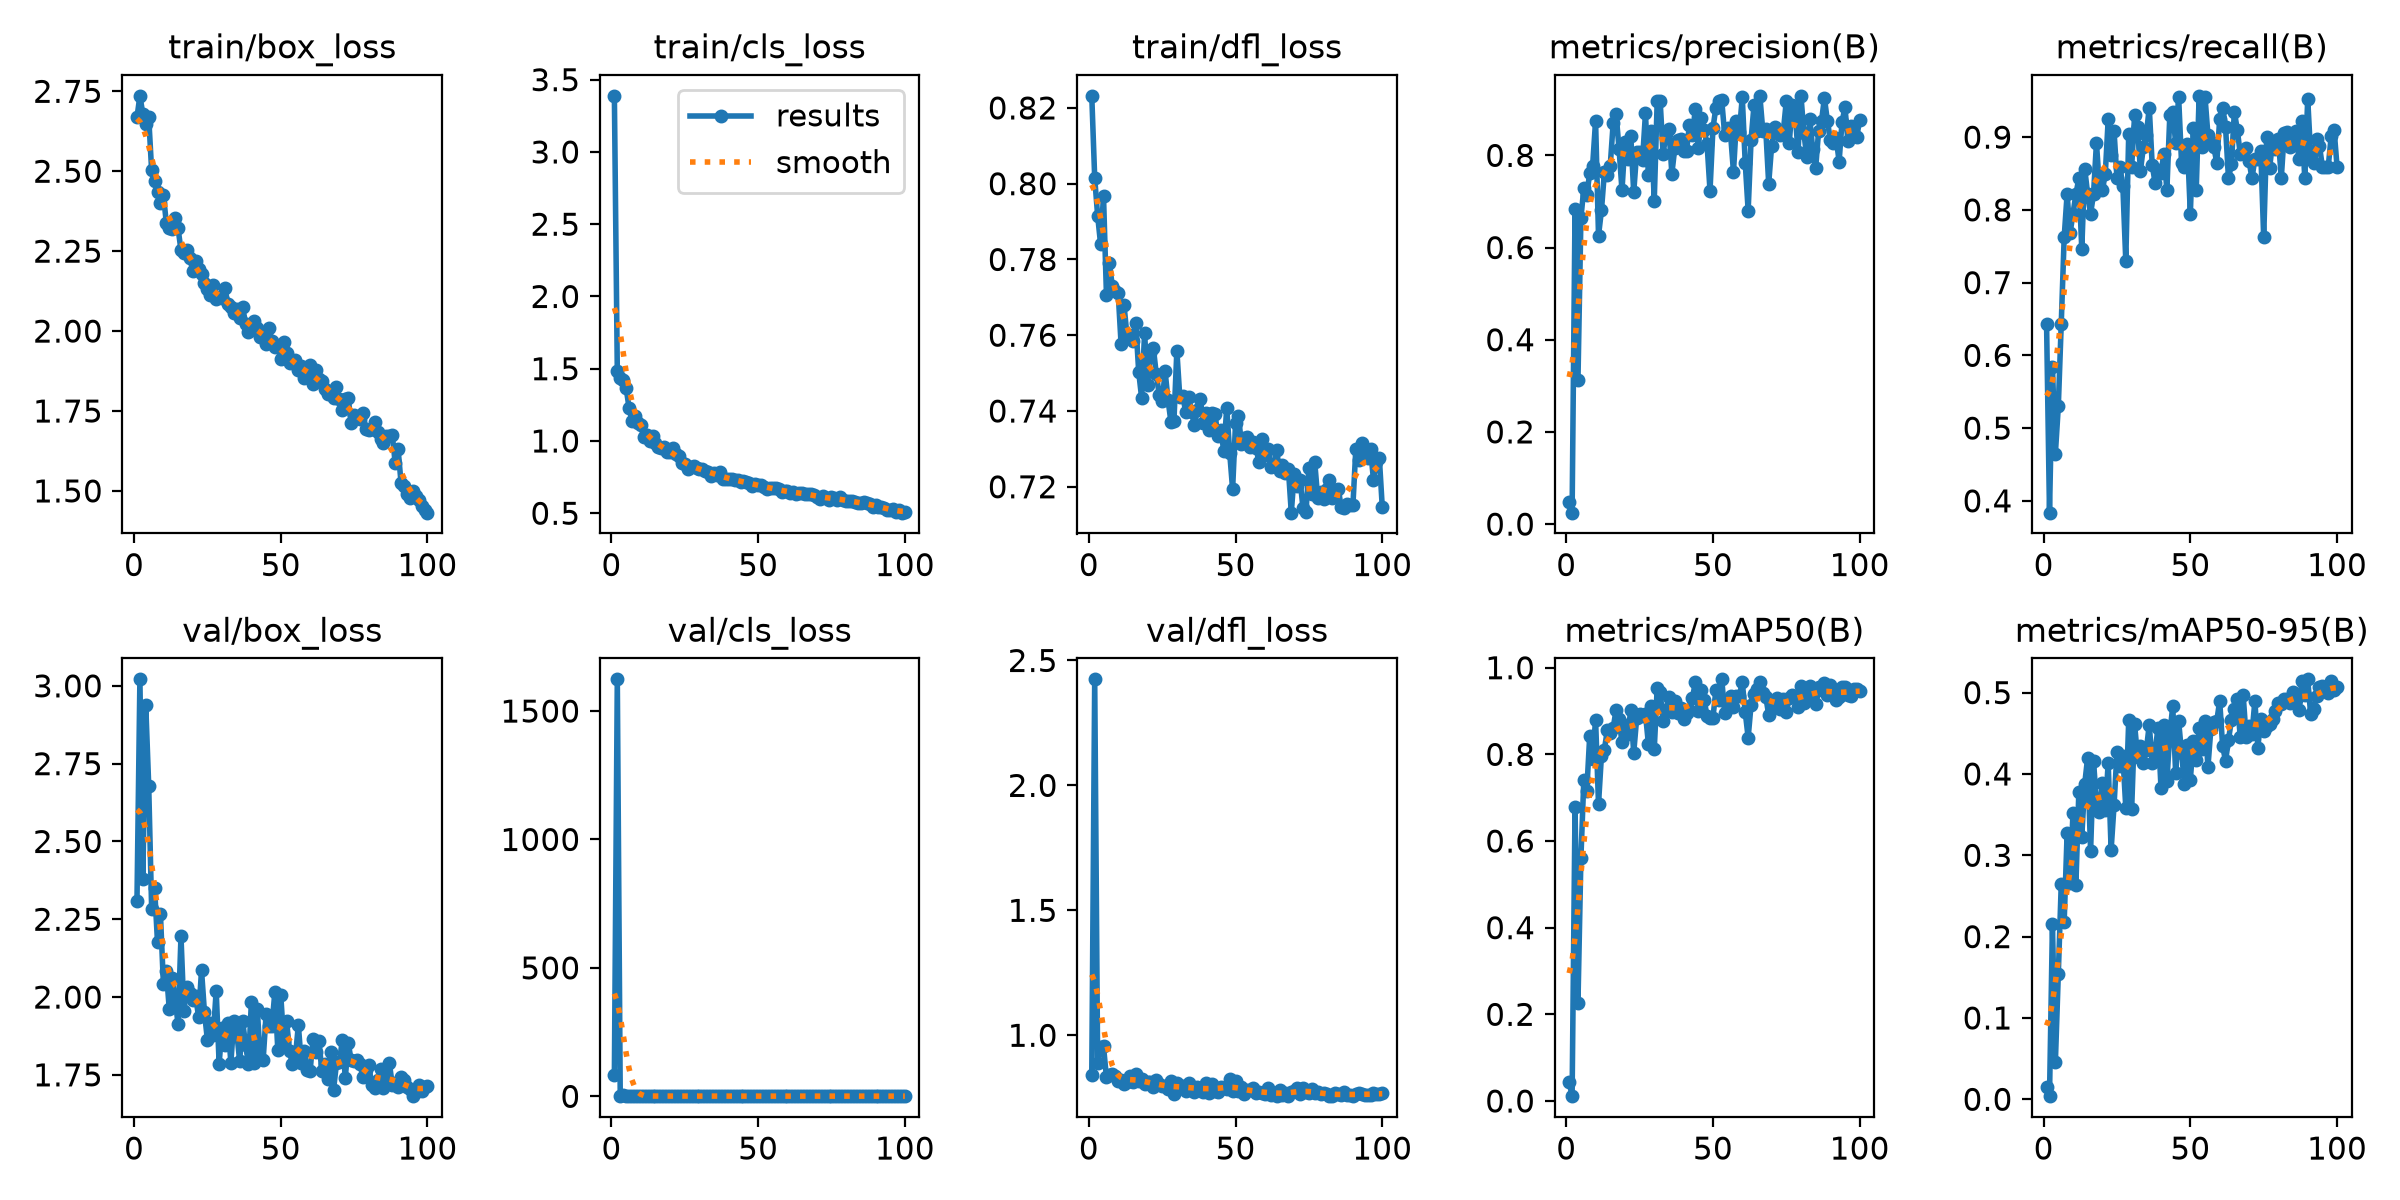

Grafico non generato da questa versione/configurazione: PR_curve.png
C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_ball\evaluation_validation\confusion_matrix.png


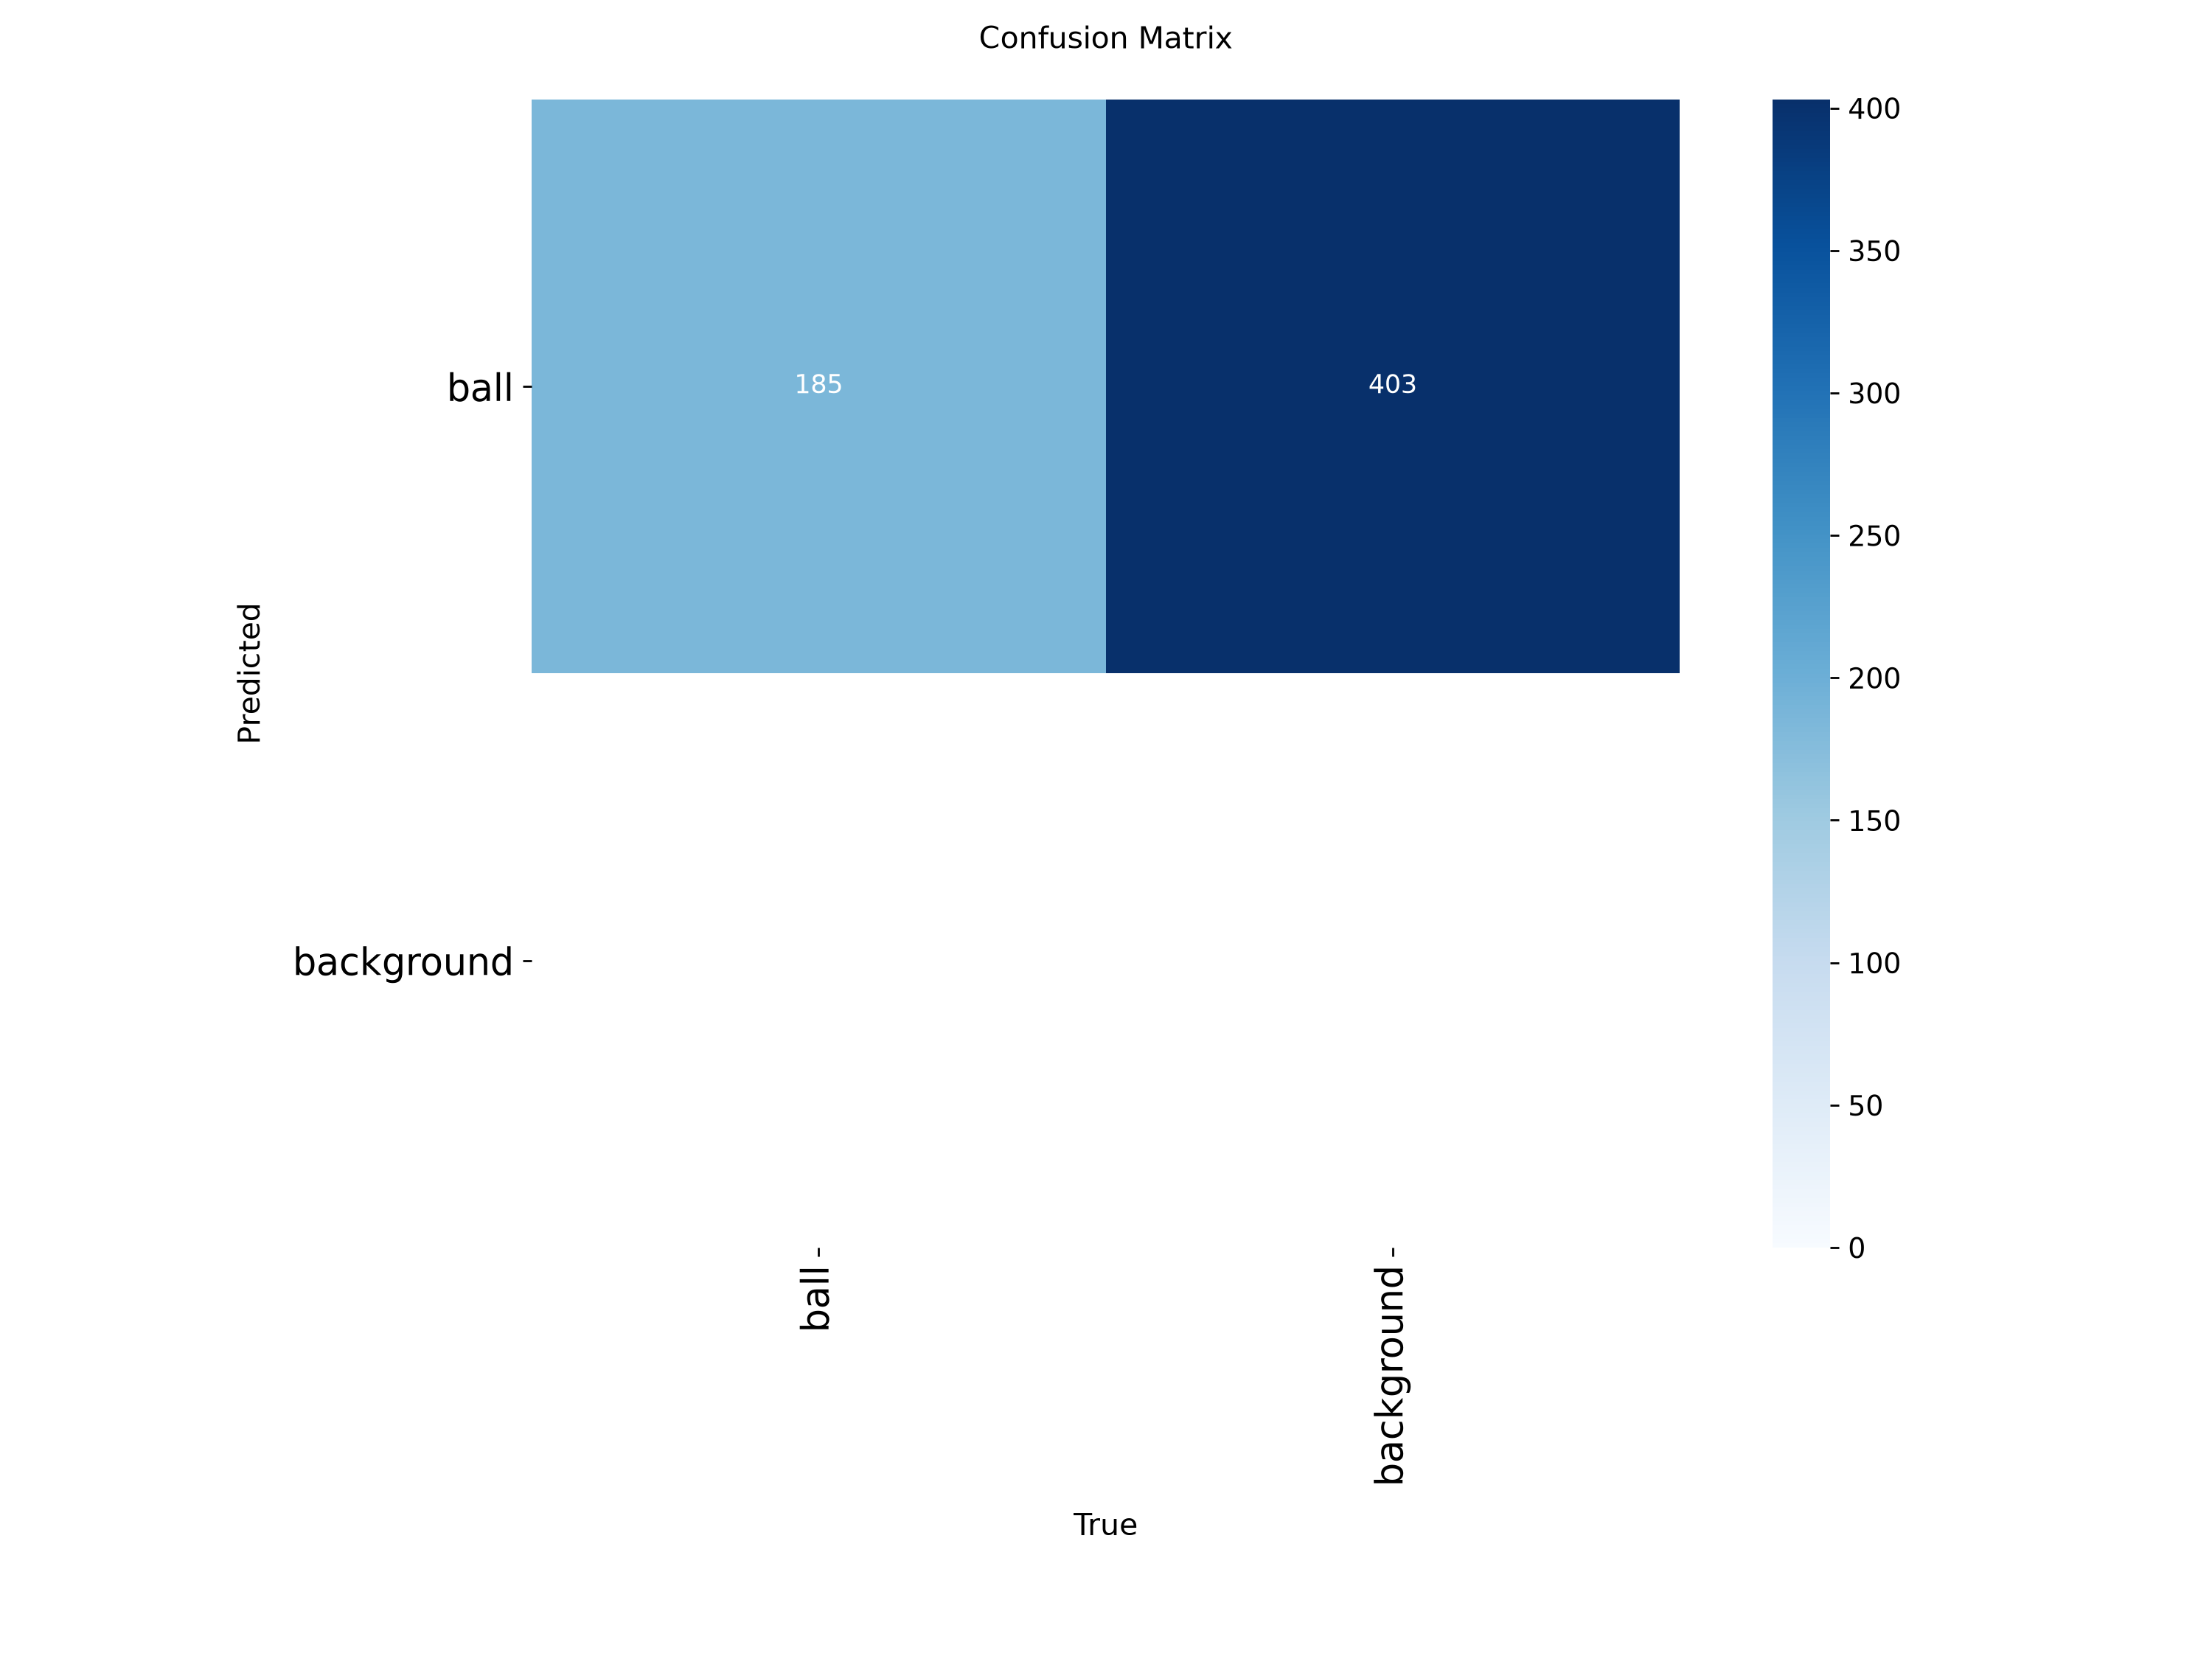

Grafico non generato da questa versione/configurazione: PR_curve.png
C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_ball\evaluation_test\confusion_matrix.png


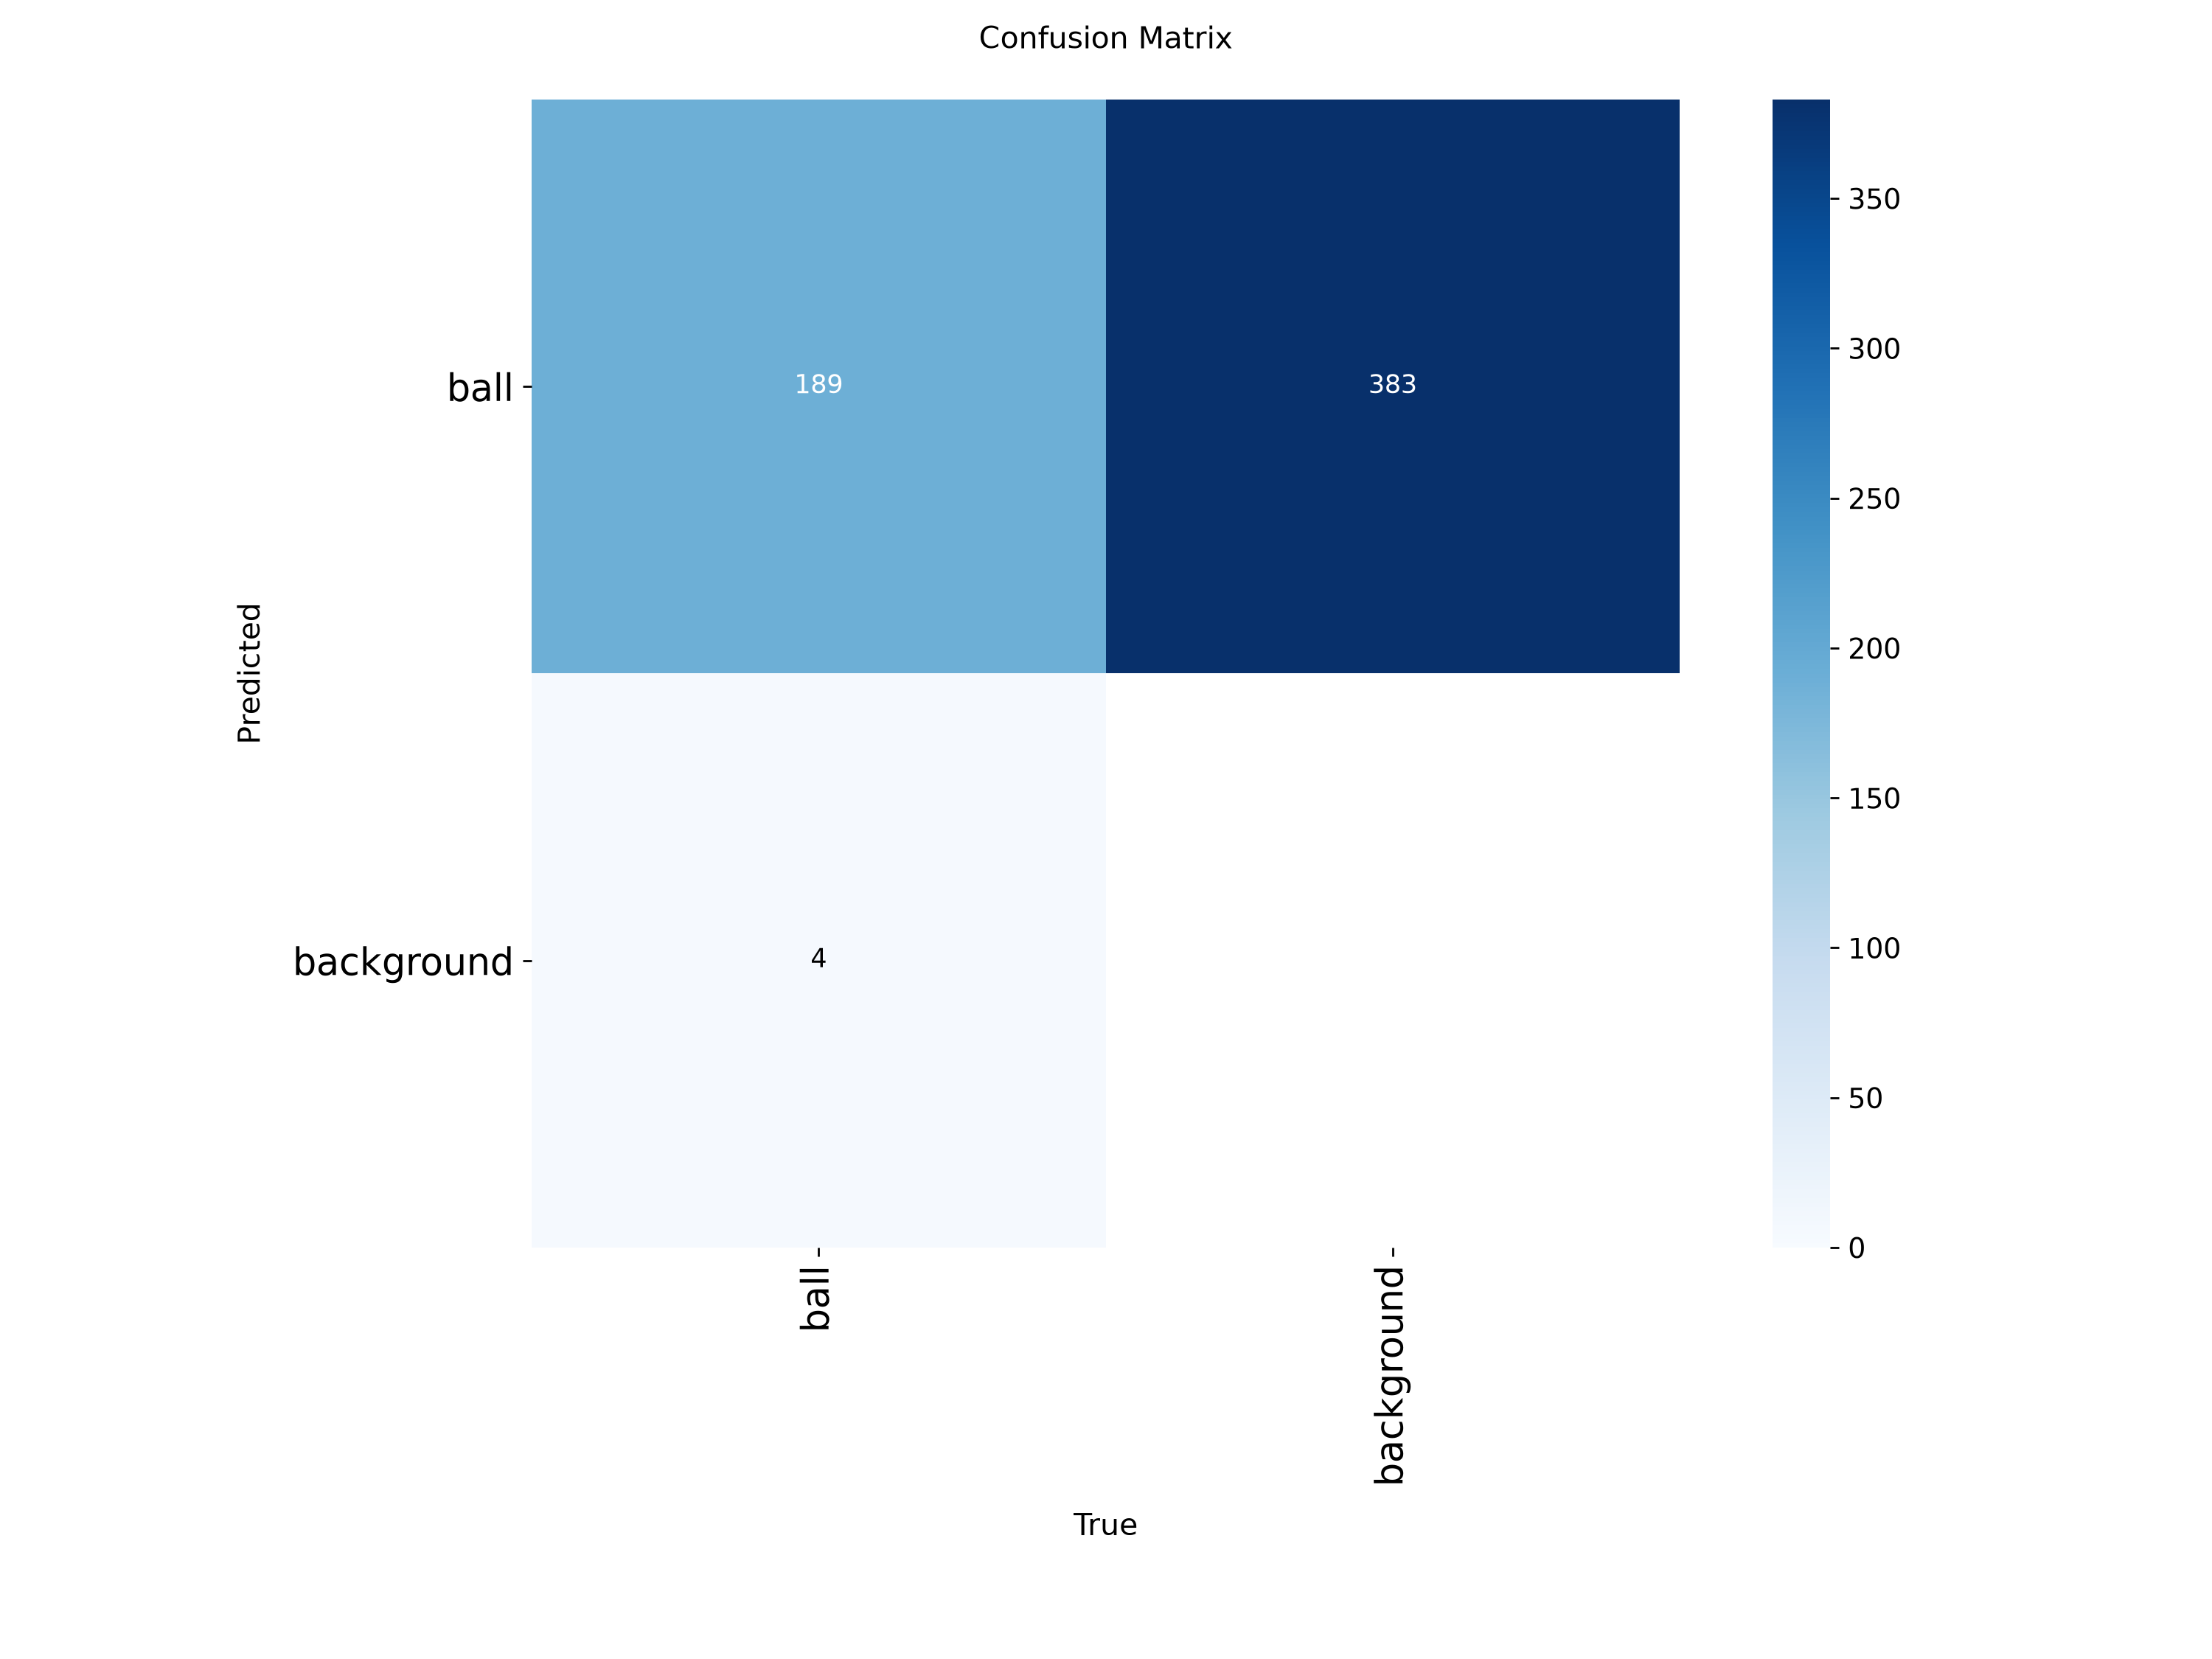

Best checkpoint: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_ball\yolov8m_ball_20261114_172150\weights\best.pt
Metriche CSV:    C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_ball\yolov8m_ball_20261114_172150\metriche_detection.csv


In [11]:
from IPython.display import display, Image as DisplayImage

plot_paths = [
    TRAIN_RUN_DIR / "results.png",
    Path(validation_result.save_dir) / "PR_curve.png",
    Path(validation_result.save_dir) / "confusion_matrix.png",
]
if test_result is not None:
    plot_paths.extend([
        Path(test_result.save_dir) / "PR_curve.png",
        Path(test_result.save_dir) / "confusion_matrix.png",
    ])
for plot_path in plot_paths:
    if plot_path.is_file():
        print(plot_path)
        display(DisplayImage(filename=str(plot_path)))
    else:
        print(f"Grafico non generato da questa versione/configurazione: {plot_path.name}")

print(f"Best checkpoint: {BEST_WEIGHTS}")
print(f"Metriche CSV:    {METRICS_CSV}")